# Corporate PD Model - step-by-step walkthrough

This notebook walks through the full model build in the order a model developer would present it
to a validator. Every step calls the same functions as `run_pipeline.py`, so the numbers match the
model documentation.

**Objective:** estimate the 1-year probability of default (PD) of a corporate borrower from its
financial ratios, map it to a rating grade, and monitor the model after deployment.

**Steps**
1. Data and SQL feature engineering
2. Weight-of-Evidence binning and Information Value
3. Variable selection funnel (IV -> correlation -> VIF -> stepwise)
4. Logistic regression and points scorecard
5. Validation: discrimination and calibration
6. Benchmark against XGBoost
7. Rating master scale
8. Monitoring framework (PSI, CSI, Gini decay, calibration)

In [1]:
import sys, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
from IPython.display import Image, display
from pdmodel import config, data, woe, selection, scorecard, master_scale, monitoring
from pdmodel import validation as V
pd.set_option("display.width", 200); pd.set_option("display.max_colwidth", 70)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

## 1. Data and SQL feature engineering

**Data:** UCI *Polish Companies Bankruptcy* dataset (Tomczak, 2016), file `5year.arff`: financial
statements from the 5th year of the observation window, with bankruptcy status **one year later**.
A 1-year horizon is used because Basel IRB PDs are defined over one year.

**Why SQL?** In a bank, model data comes from warehouses, so data preparation is done in SQL
(`sql/feature_engineering.sql`, run in DuckDB):
- unpivot to long format and profile every ratio (missing rate, percentiles) **on the training sample only**
- drop ratios with more than 20% missing values
- cap (winsorise) each ratio at its training 1st and 99th percentiles - ratios like
  `current assets / short-term liabilities` explode when the denominator is near zero
- add a data-quality feature: number of missing ratios per firm

In [2]:
raw = data.add_split(data.load_raw())
features, profile, con = data.build_features(raw)
train = features[features["sample"] == "train"].reset_index(drop=True)
test = features[features["sample"] == "test"].reset_index(drop=True)
candidates = [c for c in features.columns if c.startswith("Attr")] + ["n_missing_ratios"]
defs = data.attribute_definitions()
print(features.groupby("sample")["default_flag"].agg(firms="size", defaults="sum", default_rate="mean"))

        firms  defaults  default_rate
sample                               
test     1773       123        0.0694
train    4137       287        0.0694


In [3]:
# Data-quality profile computed in SQL - note the extreme raw min/max before capping
con.execute("""
    SELECT variable, round(missing_rate, 3) AS missing_rate, cap_low, cap_high, raw_min, raw_max, keep_flag
    FROM variable_profile ORDER BY missing_rate DESC LIMIT 6
""").df()

,variable,missing_rate,cap_low,cap_high,raw_min,raw_max,keep_flag
0,Attr37,0.4280,0.1023,"1,534.8150",-4.3258,"67,922.0000",False
1,Attr27,0.0610,-102.8831,"7,131.9730","-47,852.0000","565,940.0000",True
2,Attr45,0.0430,-11.7126,35.0282,-530.5400,"366,030.0000",True
3,Attr60,0.0430,1.3003,678.6206,0.0368,"4,818,700.0000",True
4,Attr24,0.0210,-1.1525,1.4563,-463.8900,252.3400,True
5,Attr53,0.0180,-5.1481,67.7886,"-1,088.7000","8,309.6000",True


## 2. Weight of Evidence (WoE) and Information Value (IV)

Each ratio is cut into bins (quantile pre-bins, merged until every bin holds at least 5% of firms
and the default rate moves **monotonically** across bins). Each bin is replaced by its WoE:

$$WoE = \ln\left(\frac{\%\,\text{non-defaulters in bin}}{\%\,\text{defaulters in bin}}\right)
\qquad IV = \sum (\%\text{non-def} - \%\text{def}) \times WoE$$

- Higher WoE = safer bin. WoE makes the relationship with log-odds linear, which logistic
  regression assumes, and it handles outliers and missing values (own bin) naturally.
- IV measures a variable's stand-alone predictive power: <0.02 useless, 0.02-0.1 weak,
  0.1-0.3 medium, 0.3-0.5 strong, >0.5 very strong (review for leakage).

In [4]:
binners, iv = woe.fit_all(train, candidates)
iv["strength"] = iv["iv"].apply(woe.iv_strength)
iv["definition"] = iv["variable"].map(defs)
iv.head(12)

,variable,iv,n_bins,strength,definition
0,Attr21,2.1111,7,very strong (check),sales (n) / sales (n-1)
1,Attr27,1.7235,3,very strong (check),profit on operating activities / financial expenses
2,Attr26,1.3163,7,very strong (check),(net profit + depreciation) / total liabilities
3,Attr39,1.2972,5,very strong (check),profit on sales / sales
4,Attr13,1.2877,6,very strong (check),(gross profit + depreciation) / sales
5,Attr16,1.2856,8,very strong (check),(gross profit + depreciation) / total liabilities
6,Attr35,1.2735,4,very strong (check),profit on sales / total assets
7,Attr42,1.2481,4,very strong (check),profit on operating activities / sales
8,Attr45,1.2312,7,very strong (check),net profit / inventory
9,Attr22,1.2194,4,very strong (check),profit on operating activities / total assets


In [5]:
# Example: the WoE table for the quick ratio - default rate falls steadily as liquidity improves
binners["Attr46"].table_

,variable,bin,lower,upper,n,bads,default_rate,woe,iv
0,Attr46,"[-inf, 0.3611)",-inf,0.3611,413,115,0.2785,-1.6452,0.5334
1,Attr46,"[0.3611, 0.5616)",0.3611,0.5616,412,45,0.1092,-0.5057,0.0318
2,Attr46,"[0.5616, 0.7194)",0.5616,0.7194,412,31,0.0752,-0.1006,0.0011
3,Attr46,"[0.7194, 0.8748)",0.7194,0.8748,412,20,0.0485,0.3574,0.0109
4,Attr46,"[0.8748, 1.076)",0.8748,1.0760,412,13,0.0316,0.7928,0.0450
5,Attr46,"[1.076, inf)",1.0760,inf,2062,61,0.0296,0.8879,0.2716
6,Attr46,Missing (-> riskiest bin),NaN,NaN,14,2,0.1429,-1.6452,0.0000


**Observation:** many IVs are above 0.5. That would be a red flag in an application scorecard,
but here the label is bankruptcy within one year, so distressed firms already show collapsing sales
and negative profits in their last statements. The strength is plausible, but it is flagged in the
documentation as a limitation (performance will be lower at longer horizons).

## 3. Variable selection funnel

Financial ratios are heavily correlated (many share numerators like *gross profit* or denominators
like *total assets*). The funnel keeps the model small, stable and explainable:

1. **IV >= 0.02**
2. **Correlation filter:** walking down the IV ranking, drop a variable if |corr| > 0.7 with one already kept
3. **VIF <= 5:** remove remaining multicollinearity
4. **Forward stepwise logistic regression:** add the variable that most improves log-likelihood, but
   only if every coefficient is **negative** (intuitive sign) and **significant** (p < 0.05)

In [6]:
woe_train = woe.transform_all(train, binners)
selected, funnel, stage_counts = selection.run_funnel(iv, woe_train, train["default_flag"])
print(stage_counts)
print("Selected:", selected)
funnel.assign(definition=funnel["variable"].map(defs)).query("stage != '1. IV filter'").head(12)

{'candidates': 64, 'after IV filter': 63, 'after correlation filter': 29, 'after VIF filter': 29, 'final model': 4}
Selected: ['Attr21', 'Attr27', 'Attr46', 'Attr38']


,variable,stage,reason,iv,definition
0,Attr21,Selected,kept through all stages,2.1111,sales (n) / sales (n-1)
1,Attr27,Selected,kept through all stages,1.7235,profit on operating activities / financial expenses
2,Attr46,Selected,kept through all stages,0.8938,(current assets - inventory) / short-term liabilities
3,Attr38,Selected,kept through all stages,0.6937,constant capital / total assets
5,Attr13,2. Correlation filter,|corr| 0.88 > 0.7 with Attr26 (higher IV),1.2877,(gross profit + depreciation) / sales
6,Attr16,2. Correlation filter,|corr| 0.98 > 0.7 with Attr26 (higher IV),1.2856,(gross profit + depreciation) / total liabilities
7,Attr35,2. Correlation filter,|corr| 0.92 > 0.7 with Attr39 (higher IV),1.2735,profit on sales / total assets
8,Attr42,2. Correlation filter,|corr| 0.73 > 0.7 with Attr27 (higher IV),1.2481,profit on operating activities / sales
9,Attr45,2. Correlation filter,|corr| 0.79 > 0.7 with Attr26 (higher IV),1.2312,net profit / inventory
10,Attr22,2. Correlation filter,|corr| 0.73 > 0.7 with Attr27 (higher IV),1.2194,profit on operating activities / total assets


The stepwise stage stopped at **4 variables**: no other candidate added significant information
with the correct sign once these four were in. The four cover four distinct credit-risk dimensions:

| Variable | Ratio | Risk dimension |
|---|---|---|
| Attr21 | sales (n) / sales (n-1) | Growth / business momentum |
| Attr27 | operating profit / financial expenses | Debt-service capacity (interest cover) |
| Attr46 | (current assets - inventory) / short-term liabilities | Liquidity (quick ratio) |
| Attr38 | constant capital / total assets | Capital structure / long-term funding |

In [7]:
selection.vif_table(woe_train[selected])

,variable,vif
0,Attr21,1.1582
1,Attr27,1.1772
2,Attr46,1.4348
3,Attr38,1.3976


## 4. Logistic regression and points scorecard

$$PD = \frac{1}{1 + e^{-(\beta_0 + \sum_i \beta_i \, WoE_i)}}$$

All coefficients are negative (higher WoE = safer = lower PD) and highly significant.
The model is also expressed as a **points scorecard** (600 points at 50:1 odds, 20 points to double
the odds), so a credit analyst can score a company by hand.

In [8]:
model = scorecard.PDScorecard(binners, selected).fit(train)
model.coefficient_table()

,variable,coefficient,std_error,z,p_value,ci_lower,ci_upper
0,const,-2.6487,0.0879,-30.1470,0.0000,-2.8209,-2.4765
1,Attr21,-0.7440,0.0557,-13.3584,0.0000,-0.8532,-0.6349
2,Attr27,-0.7324,0.0563,-13.0012,0.0000,-0.8428,-0.6220
3,Attr46,-0.5152,0.0899,-5.7337,0.0000,-0.6913,-0.3391
4,Attr38,-0.3856,0.1031,-3.7414,0.0002,-0.5875,-0.1836


In [9]:
model.points_table().query("variable == 'Attr27'")

,variable,bin,n,default_rate,woe,points
8,Attr27,"[-inf, -0.7961)",389,0.3085,-1.7898,103
9,Attr27,"[-0.7961, 0)",224,0.0491,0.3266,148
10,Attr27,"[0, inf)",3271,0.0229,1.1509,165
11,Attr27,Missing,253,0.3202,-1.8449,102


## 5. Validation

**Discrimination** - does the model rank risky firms above safe ones?
- **AUC**: probability a random defaulter gets a higher PD than a random non-defaulter
- **Gini** = 2 x AUC - 1 (0 = random, 1 = perfect)
- **KS**: maximum gap between the cumulative distributions of defaulters and non-defaulters

**Calibration** - are the PD *levels* right?
- **Hosmer-Lemeshow**: observed vs expected defaults across PD deciles (high p-value = good)
- **Binomial test** (one-sided): is the observed default rate significantly *above* the predicted PD?

In [10]:
pd_train, pd_test = model.predict_pd(train), model.predict_pd(test)
perf = pd.DataFrame({"train": V.performance_summary(train["default_flag"], pd_train),
                     "test": V.performance_summary(test["default_flag"], pd_test)})
perf.loc[["n", "defaults", "default_rate", "mean_pd", "auc", "gini", "gini_ci_95", "ks", "brier",
          "hosmer_lemeshow_p", "binomial_p_portfolio"]]

,train,test
n,4137,1773
defaults,287,123
default_rate,0.0694,0.0694
mean_pd,0.0694,0.0715
auc,0.9098,0.9241
gini,0.8195,0.8482
gini_ci_95,"[0.7745055545614454, 0.8552853979108554]","[0.7948489296708382, 0.8928101980619453]"
ks,0.6899,0.7049
brier,0.0397,0.0376
hosmer_lemeshow_p,0.1358,0.7977


Test Gini is slightly *higher* than train Gini. This is sampling noise (the 95% bootstrap intervals
overlap heavily), not a problem - the key point is there is **no sign of over-fitting**.

In [11]:
V.decile_table(test["default_flag"], pd_test)

,decile,n,defaults,mean_pd,default_rate,cum_capture
0,1,178,82,0.4868,0.4607,0.6667
1,2,177,22,0.1023,0.1243,0.8455
2,3,177,9,0.0433,0.0508,0.9187
3,4,177,3,0.0236,0.0169,0.9431
4,5,178,3,0.0156,0.0169,0.9675
5,6,177,2,0.0120,0.0113,0.9837
6,7,177,1,0.0096,0.0056,0.9919
7,8,177,1,0.0081,0.0056,1.0000
8,9,177,0,0.0065,0.0000,1.0000
9,10,178,0,0.0056,0.0000,1.0000


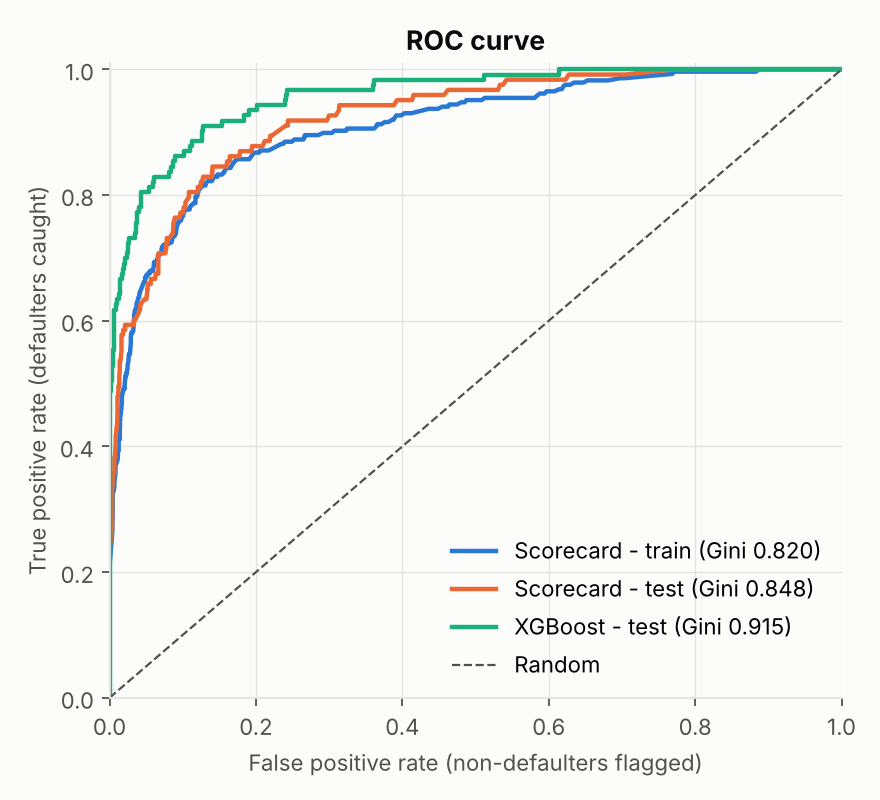

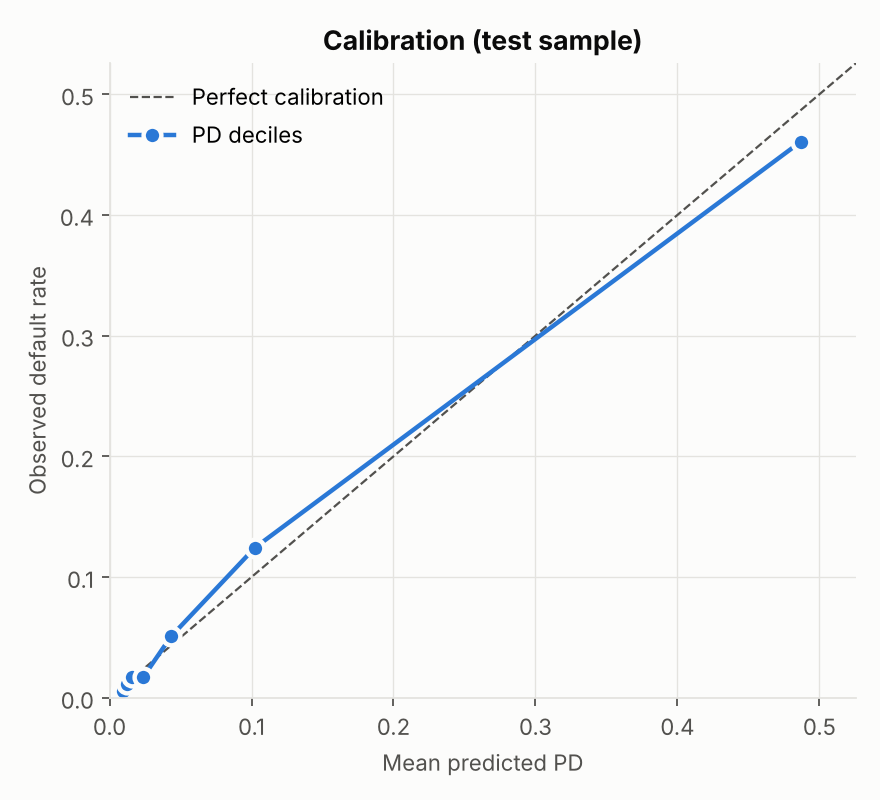

In [12]:
display(Image("../reports/figures/roc.png", width=420))
display(Image("../reports/figures/calibration.png", width=420))

**Sensitivity check.** Firms with a missing sales-growth ratio (no prior-year sales) default
at a very high rate in this sample. To make sure the model is not leaning on that data artefact,
performance is re-measured without those firms:

In [13]:
m = test["Attr21"].notna()
print(f"Test Gini, all firms: {V.gini(test['default_flag'], pd_test):.3f}")
print(f"Test Gini, excluding missing Attr21 ({m.sum()} firms): {V.gini(test.loc[m, 'default_flag'], pd_test[m.to_numpy()]):.3f}")

Test Gini, all firms: 0.848
Test Gini, excluding missing Attr21 (1736 firms): 0.791


## 6. Benchmark: XGBoost challenger

A gradient-boosted tree model on all 64 capped ratios is used as a **challenger**, not a replacement.

In [14]:
xgb = scorecard.fit_xgboost_benchmark(train, candidates)
print(f"XGBoost  Gini train {V.gini(train['default_flag'], xgb.predict_proba(train[candidates])[:,1]):.3f} | "
      f"test {V.gini(test['default_flag'], xgb.predict_proba(test[candidates])[:,1]):.3f}")
print(f"Scorecard Gini train {V.gini(train['default_flag'], pd_train):.3f} | test {V.gini(test['default_flag'], pd_test):.3f}")

XGBoost  Gini train 0.995 | test 0.915
Scorecard Gini train 0.820 | test 0.848


XGBoost ranks better on the test set (~7 Gini points) but uses 64 inputs, shows a large train/test
gap (over-fitting risk) and cannot be explained bin by bin. In a regulated bank, model risk
guidance (e.g. SR 11-7, ECB TRIM) favours a transparent, stable model whose drivers credit officers
understand - so the 4-variable scorecard is the champion and XGBoost is kept as a benchmark.

## 7. Rating master scale

PDs are mapped to **8 grades** with fixed PD bands (chosen on the training sample). A good master
scale is **monotonic** (worse grade -> higher default rate) and **calibrated** (observed default
rate inside the confidence interval of the grade PD).

In [15]:
gt = master_scale.grade_table(test["default_flag"], pd_test)
print("Monotonic on test:", master_scale.is_monotonic(gt))
gt

Monotonic on test: True


,grade,pd_lower,pd_upper,n,defaults,mean_pd,share,observed_dr,dr_ci_low,dr_ci_high,binomial_p
0,G1,0.0000,0.0065,270,0,0.0058,0.1523,0.0000,0.0000,0.0093,1.0000
1,G2,0.0065,0.0100,386,2,0.0082,0.2177,0.0052,0.0011,0.0165,0.8245
2,G3,0.0100,0.0150,276,3,0.0121,0.1557,0.0109,0.0031,0.0287,0.6485
3,G4,0.0150,0.0300,302,5,0.0202,0.1703,0.0166,0.0063,0.0359,0.7309
4,G5,0.0300,0.0600,181,9,0.0425,0.1021,0.0497,0.0249,0.0888,0.3641
5,G6,0.0600,0.1500,162,18,0.0942,0.0914,0.1111,0.0696,0.1663,0.2652
6,G7,0.1500,0.3500,97,15,0.2412,0.0547,0.1546,0.0933,0.2363,0.9861
7,G8,0.3500,1.0000,99,71,0.6698,0.0558,0.7172,0.6231,0.7987,0.1858


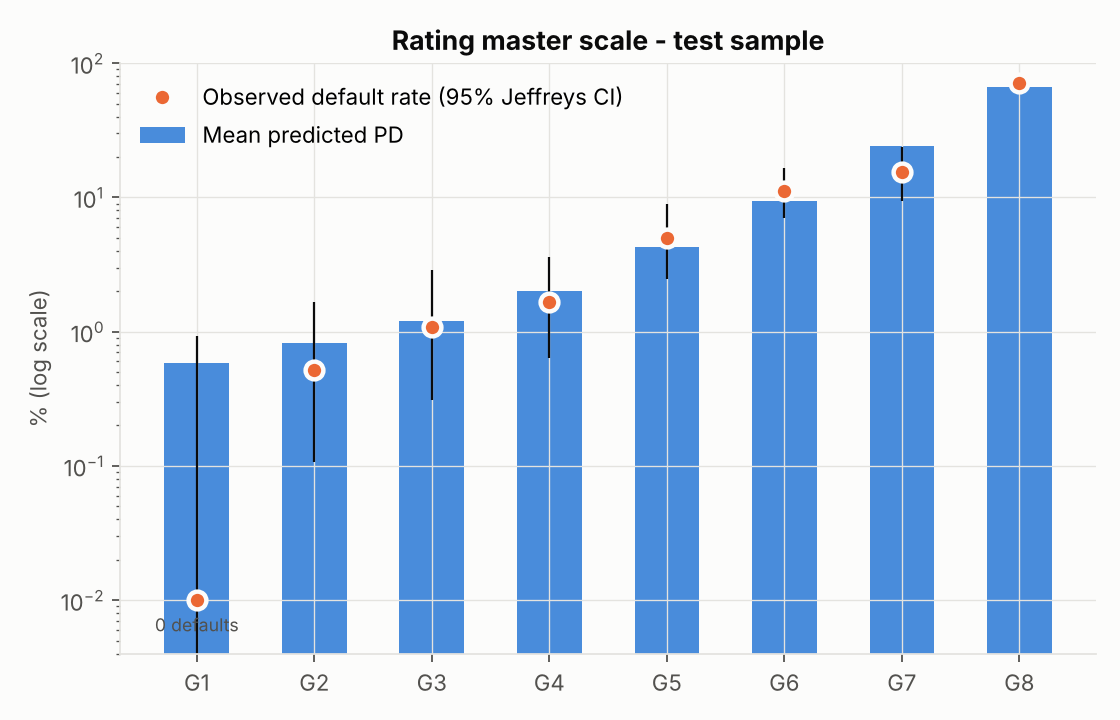

In [16]:
display(Image("../reports/figures/master_scale.png", width=560))

## 8. Monitoring framework

After deployment the model is reviewed quarterly. There is no post-development data for this
dataset, so four quarters are **simulated** from the hold-out sample with controlled drift:

| Quarter | Scenario | Risk tilt | Ratio noise | Default uplift |
|---|---|---|---|---|
| Q1 | business as usual | 0 | 0 | 1.0x |
| Q2 | mild deterioration | 0.12 | 0.10 | 1.15x |
| Q3 | moderate downturn | 0.25 | 0.35 | 1.4x |
| Q4 | severe stress | 0.40 | 0.70 | 2.0x |

- **PSI** on the score (vs development deciles): <0.10 Green, 0.10-0.25 Amber, >0.25 Red
- **CSI** per model variable - points to *which* input is shifting
- **Relative Gini drop** vs development: <5% Green, 5-10% Amber, >10% Red
- **Binomial test** of observed defaults vs mean PD: p >= 0.05 Green, 0.01-0.05 Amber, < 0.01 Red

In [17]:
mon = monitoring.run_monitoring(model, train, test, profile, V.gini(test["default_flag"], pd_test))
mon["summary"][["quarter", "observed_dr", "mean_pd", "psi", "psi_rag", "gini", "gini_relative_drop",
                "gini_rag", "binomial_p", "calibration_rag", "overall_rag"]]

,quarter,observed_dr,mean_pd,psi,psi_rag,gini,gini_relative_drop,gini_rag,binomial_p,calibration_rag,overall_rag
0,Q1,0.0722,0.0739,0.0136,Green,0.8748,-0.0313,Green,0.6214,Green,Green
1,Q2,0.0993,0.0932,0.0452,Green,0.8621,-0.0164,Green,0.1993,Green,Green
2,Q3,0.1410,0.1238,0.1987,Amber,0.7885,0.0704,Amber,0.0165,Amber,Amber
3,Q4,0.2363,0.1897,0.5669,Red,0.7693,0.0930,Amber,0.0000,Red,Red


In [18]:
mon["csi"]

,quarter,Attr21,Attr27,Attr46,Attr38
0,Q1,0.0074,0.0039,0.0031,0.0083
1,Q2,0.0313,0.0739,0.0128,0.0165
2,Q3,0.0827,0.1853,0.0705,0.0316
3,Q4,0.2713,0.4088,0.3251,0.1646


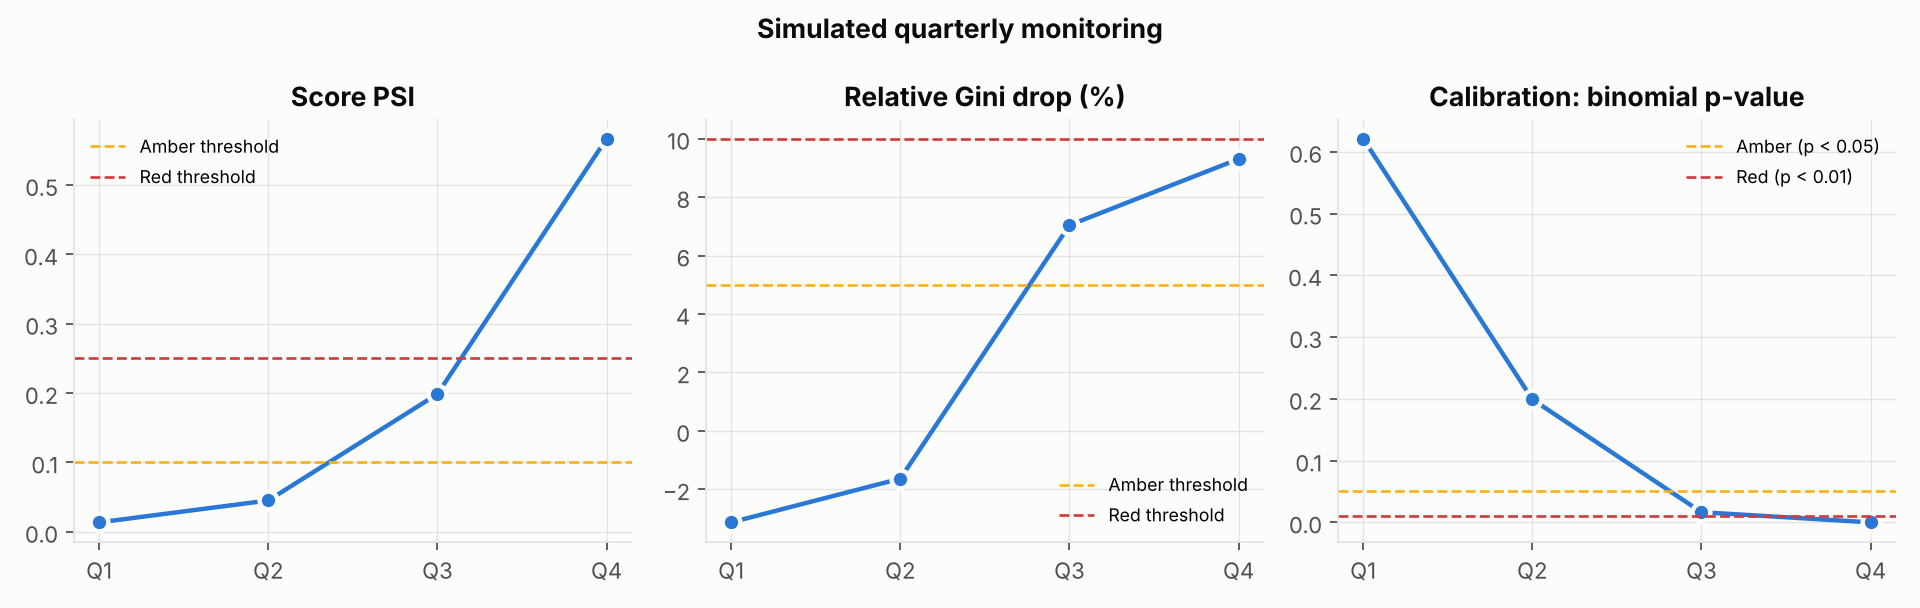

In [19]:
display(Image("../reports/figures/monitoring.png", width=900))

**Reading the results:** Q1 and Q2 stay Green. In Q3 all three metrics turn Amber - the portfolio
is shifting (PSI 0.2), ranking power is slipping and defaults are running above predicted PDs.
In Q4 PSI and calibration are Red: the model would be escalated for redevelopment or a PD
recalibration (e.g. adjusting the intercept to the new central tendency). CSI shows the shift is
driven mainly by `Attr27` (interest cover), which is where a credit analyst would look first.

The full quarterly report with RAG colouring is in `reports/monitoring_report.xlsx`.